# Where cells sit in the cycle

A drug that stops the cell cycle leaves its mark in the DNA content of the cells it stopped. This tutorial places
single cells on the cycle from their DNA stain with {func}`~mantispy.tl.fit_cell_cycle` and
{func}`~mantispy.tl.project_cell_cycle`, and checks the result against drugs whose effect on the cycle is known.

The data are MCF-7 nuclei from BBBC021 ({func}`~mantispy.ds.bbbc021_cells`): fifteen compounds in three replicate
wells each, and one DMSO well from every plate they sit on. Each mechanism of action predicts a place in the cycle,
so we state the predictions before looking:

| Mechanism | Prediction |
| --- | --- |
| Microtubule destabilizers and stabilizers, Eg5 inhibitors | stop cells in mitosis, so more cells at 4N and more flagged as mitotic |
| Aurora kinase inhibitors | let cells skip division, so cells above 4N |
| DNA replication inhibitors | stall replication, so more cells in S |
| DNA damage | stop cells before mitosis, so more cells in G2 |
| Cholesterol-lowering (statins) | no cell-cycle target, so the same distribution as DMSO |

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import mantispy as mt

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

cells = mt.ds.bbbc021_cells()
cells.obs.groupby("Metadata_MOA", observed=True)["Metadata_Compound"].agg(["nunique", "size"]).rename(
    columns={"nunique": "compounds", "size": "nuclei"}
)

,compounds,nuclei
Metadata_MOA,,
Aurora kinase inhibitors,2,3081
Cholesterol-lowering,2,1100
DMSO,1,22509
DNA damage,2,3946
DNA replication,3,3719
Eg5 inhibitors,2,1934
Microtubule destabilizers,2,1537
Microtubule stabilizers,2,1672


## DNA content

{func}`~mantispy.tl.dna_content` turns the integrated DAPI intensity into doublings of the G1 peak, so a 2N nucleus
sits near 0 and a 4N nucleus near 1. The G1 peak is normally measured in each well, since staining differs between
wells. Here that would fail. A well of arrested cells has no G1 peak of its own, and its 4N peak would be taken for
one. So the peak is measured on the DMSO cells of each plate (``reference="negcon"``) and applied to every well on
that plate.

In [2]:
mt.tl.dna_content(
    cells, dna_feature="Nuclei_Intensity_IntegratedIntensity_DAPI", by="Metadata_Plate", reference="negcon"
)

## The DMSO clock

{func}`~mantispy.tl.fit_cell_cycle` fits the clock on the DMSO cells. It first checks that they cycle: a 2N peak, a
separate 4N peak and S cells between them. It then orders the cells G1, S, G2 and M by DNA content and turns each
cell's cumulative share into a position in the cycle, corrected for the age distribution of a growing population.
The mean DAPI intensity and the nuclear area let it flag mitotic nuclei, which are brighter and smaller than the
other nuclei of the same DNA content.

In [3]:
mt.tl.fit_cell_cycle(
    cells, reference="negcon", mitosis_features=("Nuclei_Intensity_MeanIntensity_DAPI", "Nuclei_AreaShape_Area")
)
model = cells.uns["mantispy"]["cell_cycle"]
print("DMSO shares of G1, S, G2 and M:", np.round(model["fractions"], 3))
pd.Series(model["gate"]).round(3)

DMSO shares of G1, S, G2 and M: [0.567 0.247 0.185 0.002]


peak_4n          0.88
peak_ratio      0.504
valley_ratio    0.595
s_floor         0.595
s_share          0.23
passed              1
dtype: object

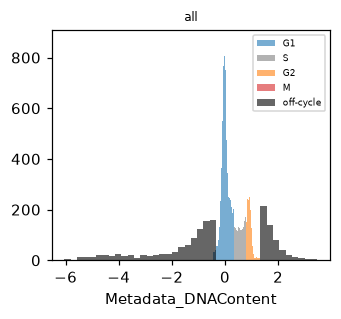

In [4]:
mt.tl.project_cell_cycle(cells)
dmso = cells[cells.obs["Metadata_MOA"] == "DMSO"]
mt.pl.cell_cycle(dmso, dna_feature="Metadata_DNAContent", key="cell_cycle_phase", by=None)

{func}`~mantispy.tl.project_cell_cycle` placed every nucleus on the DMSO clock. Each one has a phase, a
position from 0 (the start of G1) to 1 (division), and an interval around that position. An S nucleus is placed
tightly, because its DNA content says how far replication has gone. A G1 or G2 nucleus gets its whole plateau as
the interval, because DNA content does not order cells within it. A nucleus outside the DMSO DNA range, below 2N or
above 4N, is off the cycle.

## Phases by mechanism

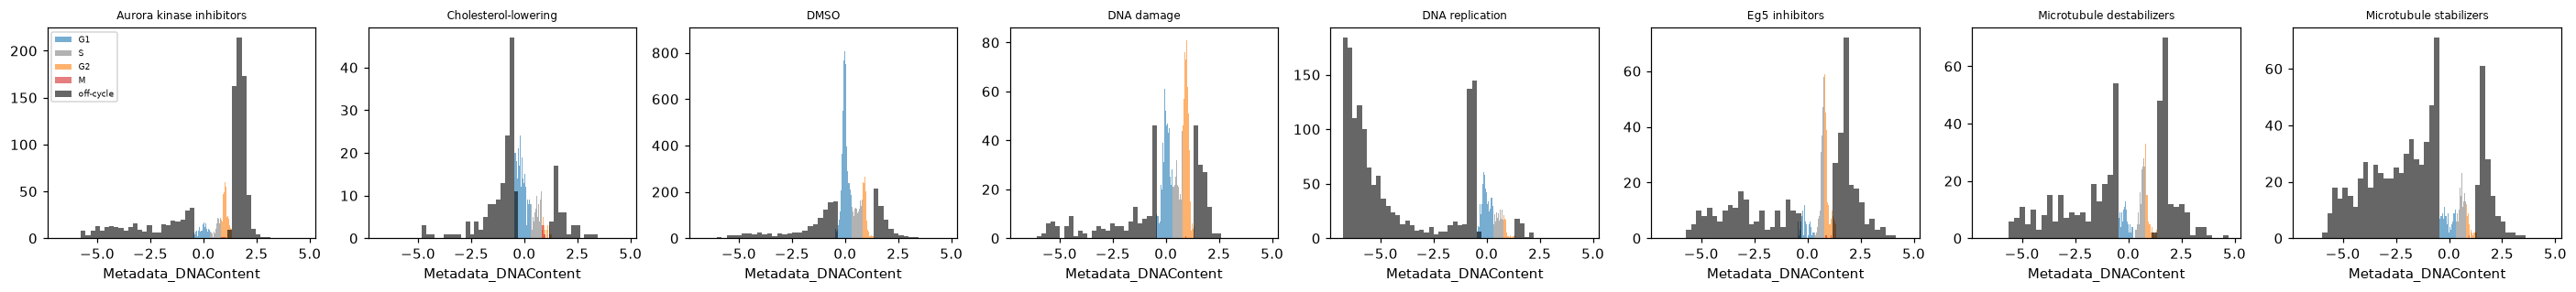

In [5]:
mt.pl.cell_cycle(cells, dna_feature="Metadata_DNAContent", key="cell_cycle_phase", by="Metadata_MOA")

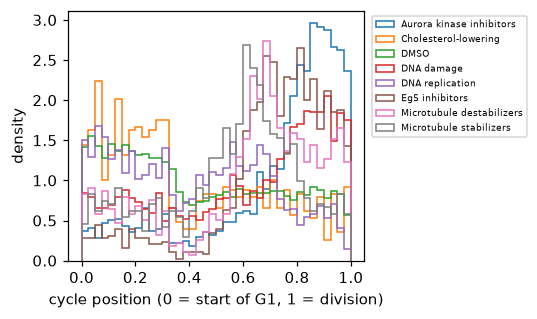

In [6]:
mt.pl.cell_cycle(cells, position="cell_cycle", by="Metadata_MOA")

The occupancy plot draws one position per nucleus from its interval, so a mechanism that piles cells up at
one place in the cycle stands out against DMSO. The table puts numbers on both plots: each mechanism's share of
nuclei per phase minus the DMSO share, with the off-cycle nuclei split into those below 2N and those above 4N.

In [7]:
obs = cells.obs
low, high = model["off_cycle"]
phase = obs["cell_cycle_phase"].astype(str).where(obs["cell_cycle_phase"] != "off-cycle", "")
phase[obs["Metadata_DNAContent"] < low] = "below 2N"
phase[obs["Metadata_DNAContent"] > high] = "above 4N"
share = pd.crosstab(obs["Metadata_MOA"], phase, normalize="index")[["G1", "S", "G2", "M", "below 2N", "above 4N"]]
share["mitotic flag"] = obs.groupby("Metadata_MOA", observed=True)["cell_cycle_mitotic"].mean()
change = share - share.loc["DMSO"]
change.drop(index="DMSO").round(3)

cell_cycle_phase,G1,S,G2,M,below 2N,above 4N,mitotic flag
Metadata_MOA,,,,,,,
Aurora kinase inhibitors,-0.404,-0.077,0.235,0.009,0.060,0.177,0.004
Cholesterol-lowering,-0.027,-0.010,-0.094,0.028,0.089,0.015,0.191
DNA damage,-0.237,0.005,0.227,-0.001,-0.001,0.007,-0.013
DNA replication,-0.189,-0.007,-0.122,-0.002,0.334,-0.014,-0.011
Eg5 inhibitors,-0.445,0.163,0.132,0.011,0.056,0.084,0.005
Microtubule destabilizers,-0.358,0.144,0.001,0.001,0.121,0.090,-0.013
Microtubule stabilizers,-0.360,0.090,-0.085,-0.001,0.294,0.062,-0.013


## Checking the predictions

Each prediction becomes a rule on the table above, with a change of 0.05 (five percentage points of nuclei) as the
smallest one that counts.

In [8]:
rules = {
    "Microtubule destabilizers": (
        "G2 + M up and mitotic flag up",
        lambda c: c["G2"] + c["M"] > 0.05 and c["mitotic flag"] > 0.05,
    ),
    "Microtubule stabilizers": (
        "G2 + M up and mitotic flag up",
        lambda c: c["G2"] + c["M"] > 0.05 and c["mitotic flag"] > 0.05,
    ),
    "Eg5 inhibitors": ("G2 + M up and mitotic flag up", lambda c: c["G2"] + c["M"] > 0.05 and c["mitotic flag"] > 0.05),
    "Aurora kinase inhibitors": ("above 4N up", lambda c: c["above 4N"] > 0.05),
    "DNA replication": ("S up", lambda c: c["S"] > 0.05),
    "DNA damage": ("G2 up", lambda c: c["G2"] > 0.05),
    "Cholesterol-lowering": ("no phase moves", lambda c: (c[["G1", "S", "G2", "M"]].abs() <= 0.05).all()),
}
pd.DataFrame(
    [(moa, rule, bool(test(change.loc[moa]))) for moa, (rule, test) in rules.items()],
    columns=["mechanism", "prediction", "holds"],
).set_index("mechanism")

,prediction,holds
mechanism,,
Microtubule destabilizers,G2 + M up and mitotic flag up,False
Microtubule stabilizers,G2 + M up and mitotic flag up,False
Eg5 inhibitors,G2 + M up and mitotic flag up,False
Aurora kinase inhibitors,above 4N up,True
DNA replication,S up,False
DNA damage,G2 up,True
Cholesterol-lowering,no phase moves,False


Two predictions hold. The Aurora kinase inhibitors put cells above 4N, and the DNA damage drugs put cells in
G2. The other five fail. A mechanism mixes compounds, so the same table per compound shows which of them carry each
result.

In [9]:
by_compound = pd.crosstab(obs["Metadata_Perturbation"], phase, normalize="index")[
    ["G1", "S", "G2", "M", "below 2N", "above 4N"]
]
moa_of = obs.groupby("Metadata_Perturbation", observed=True)["Metadata_MOA"].first()
(by_compound - by_compound.loc["DMSO@0.0"]).drop(index="DMSO@0.0").assign(mechanism=moa_of).sort_values(
    "mechanism"
).round(2)

cell_cycle_phase,G1,S,G2,M,below 2N,above 4N,mechanism
Metadata_Perturbation,,,,,,,
AZ258@1.0,-0.42,0.02,0.14,0.01,0.03,0.22,Aurora kinase inhibitors
AZ841@1.0,-0.39,-0.15,0.30,0.01,0.08,0.15,Aurora kinase inhibitors
mevinolin/lovastatin@15.0,-0.02,-0.04,-0.06,0.03,0.06,0.02,Cholesterol-lowering
simvastatin@20.0,-0.04,0.01,-0.13,0.02,0.11,0.01,Cholesterol-lowering
etoposide@3.0,-0.25,-0.09,0.34,-0.00,-0.01,0.02,DNA damage
mitomycin C@1.0,-0.22,0.10,0.12,-0.00,0.01,-0.01,DNA damage
camptothecin@0.03,-0.30,0.33,-0.02,-0.00,-0.01,0.00,DNA replication
floxuridine@30.0,-0.28,-0.12,-0.15,-0.00,0.56,-0.02,DNA replication
methotrexate@10.0,0.02,-0.08,-0.15,-0.00,0.23,-0.02,DNA replication


## Where the predictions fail

For every microtubule drug and Eg5 inhibitor, the G1 share fell by 0.33 to 0.45. The cells left G1, but not for
the place the prediction put them. The next table looks at the nuclei in the upper half of the cycle, with DNA content above
0.4. Per mechanism it gives the median mean DAPI intensity and the median area on a log scale, relative to the DMSO
cells of the same plate, and the 4N peak of the DNA content.

In [10]:
feats = cells[:, ["Nuclei_Intensity_MeanIntensity_DAPI", "Nuclei_AreaShape_Area"]].to_df()
logs = np.log(feats).set_axis(["mean DAPI", "area"], axis=1)
dmso_median = logs[obs["Metadata_MOA"] == "DMSO"].groupby(obs["Metadata_Plate"], observed=True).median()
logs -= dmso_median.reindex(obs["Metadata_Plate"]).to_numpy()
upper = obs["Metadata_DNAContent"] > 0.4
by_moa = obs.loc[upper, "Metadata_MOA"]
bins = np.arange(0.4, 1.41, 0.05)
peak = (
    obs.loc[upper, "Metadata_DNAContent"]
    .groupby(by_moa, observed=True)
    .agg(lambda s: bins[np.histogram(s, bins)[0].argmax()] + 0.025)
)
logs[upper].groupby(by_moa, observed=True).median().assign(**{"4N peak": peak}).round(2)

,mean DAPI,area,4N peak
Metadata_MOA,,,
Aurora kinase inhibitors,0.08,0.50,1.02
Cholesterol-lowering,0.52,-0.16,0.58
DMSO,0.13,0.21,0.92
DNA damage,0.04,0.38,0.87
DNA replication,-0.03,0.33,0.68
Eg5 inhibitors,0.27,0.18,0.78
Microtubule destabilizers,0.07,0.37,0.72
Microtubule stabilizers,0.04,0.33,0.62


The microtubule drugs put their 4N peak at 0.62 to 0.72, and the Eg5 inhibitors at 0.78, below the DMSO peak
at 0.92. The DMSO clock calls many nuclei at that DNA content S, which is why S rises and G2 does not for the
microtubule drugs. The Eg5 inhibitors sit closer to the DMSO peak and do raise G2. Neither group trips the mitosis
flag, which looks for nuclei that are both small and bright. The microtubule drugs give larger nuclei than DMSO and
no brighter ones. The Eg5 inhibitors give brighter nuclei of about the same size. The data do not say why the
stopped cells measure low in DNA content. They show that on these images, cells these drugs stop in mitosis read as
late S or G2 from DNA content alone.

The statins fail the other way. Their nuclei are smaller and brighter than DMSO nuclei, and the flag calls about
one in five of them mitotic. The flag is not specific to mitosis. It fires on any nucleus that is small and bright
for its DNA content.

The DNA replication drugs split. Camptothecin moves cells into S. Floxuridine and methotrexate move many cells below
2N, and a table by well shows where these come from.

In [11]:
wells = obs.assign(area=feats["Nuclei_AreaShape_Area"], below_2N=obs["Metadata_DNAContent"] < low)
wells = wells[wells["Metadata_MOA"].isin(["DNA replication", "Cholesterol-lowering"])]
wells.groupby(["Metadata_Perturbation", "Metadata_Plate"], observed=True).agg(
    nuclei=("area", "size"),
    median_area=("area", "median"),
    median_dna=("Metadata_DNAContent", "median"),
    below_2N=("below_2N", "mean"),
    mitotic_flag=("cell_cycle_mitotic", "mean"),
).round(2)

nuclei  median_area  median_dna  \
Metadata_Perturbation     Metadata_Plate                                    
camptothecin@0.03         Week8_38203        255       1168.0        0.60   
                          Week8_38221        327       1215.0        0.61   
                          Week8_38241        234       1222.5        0.76   
floxuridine@30.0          Week9_39282       1210         55.0       -5.84   
                          Week9_39283        366       1138.0        0.20   
                          Week9_39301        192       1142.5        0.18   
methotrexate@10.0         Week2_24121        324        975.5       -0.07   
                          Week2_24141        459       1001.0       -0.63   
                          Week2_24161        352        982.0       -0.07   
mevinolin/lovastatin@15.0 Week9_39206         79        602.0       -0.05   
                          Week9_39221        311        643.0        0.07   
                          Week9_39222        131        583.0        0.06   
simvastatin@20.0          Week9_39282         85        694.0        0.46   
                          Week9_39283        419        605.0       -0.22   
                          Week9_39301         75        577.0       -0.19   

                                          below_2N  mitotic_flag  
Metadata_Perturbation     Metadata_Plate                          
camptothecin@0.03         Week8_38203         0.04          0.01  
                          Week8_38221         0.03          0.00  
                          Week8_38241         0.02          0.01  
floxuridine@30.0          Week9_39282         0.87          0.00  
                          Week9_39283         0.03          0.01  
                          Week9_39301         0.03          0.02  
methotrexate@10.0         Week2_24121         0.05          0.01  
                          Week2_24141         0.59          0.00  
                          Week2_24161         0.04          0.01  
mevinolin/lovastatin@15.0 Week9_39206         0.18          0.18  
                          Week9_39221         0.10          0.19  
                          Week9_39222         0.06          0.24  
simvastatin@20.0          Week9_39282         0.06          0.39  
                          Week9_39283         0.14          0.20  
                          Week9_39301         0.35          0.08

In one floxuridine well, the 1,210 objects have a median area of 55 pixels, against more than 1,100 in the other
two wells. The segmentation picked up debris there, not nuclei. One methotrexate well has 59% of its nuclei below 2N
at normal size. The other wells of both drugs have a median DNA content close to 0, the G1 peak, and the table per
compound shows no gain in S for either drug. A table by mechanism hides problems like these, so check the wells before reading it.